# RAG vs Vision-Only QA

This notebook compares GPT-4.1-mini answers on the same 452 M3SciQA validation questions with and without BM25-retrieved evidence. It reads saved JSONL outputs only; it does not call any model or API.

The RAG corpus is the split's public `evidence_reference` annotations grouped by reference paper ID. This is annotation-assisted evidence answering, not open-corpus retrieval. Test answers are hidden, so this analysis is validation-only.

## 1. Set Up Notebook Environment

Import the analysis and plotting libraries and apply a consistent chart style.

In [27]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 100)

print(f"pandas {pd.__version__}; NumPy {np.__version__}; seaborn {sns.__version__}")

pandas 3.1.0; NumPy 2.5.4; seaborn 0.13.2


## 2. Create or Load Data Objects

Load the saved vision-only and RAG JSONL predictions, pair rows by `row_id`, verify complete coverage, and calculate EM, token F1, and ROUGE-L F1 from each prediction and its ground-truth answer.

In [28]:
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "results").is_dir():
    REPO_ROOT = next(
        parent for parent in Path.cwd().parents if (parent / "results").is_dir()
    )

import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

BASELINE_PATH = REPO_ROOT / "results/qa/validation/predictions.jsonl"
RAG_PATH = REPO_ROOT / "results/qa/validation/agentic-run-2026-10-31/rag-predictions-complete.jsonl"


def load_jsonl(path):
    with path.open(encoding="utf-8") as stream:
        return [json.loads(line) for line in stream if line.strip()]


baseline_rows = load_jsonl(BASELINE_PATH)
rag_rows = load_jsonl(RAG_PATH)
baseline_by_id = {row["row_id"]: row for row in baseline_rows}
assert len(baseline_rows) == len(rag_rows) == 452
assert set(baseline_by_id) == {row["row_id"] for row in rag_rows}

from llm_agents.benchmark import _normalize_answer, _token_f1, _rouge_l_f1

paired = []
for rag_row in rag_rows:
    baseline_row = baseline_by_id[rag_row["row_id"]]
    reference = rag_row.get("reference_answer") or ""
    record = {
        "row_id": rag_row["row_id"],
        "modality": rag_row.get("modality", "unknown"),
        "reference": reference,
        "vision_only_prediction": baseline_row["prediction"],
        "rag_prediction": rag_row["prediction"],
    }
    for name, prediction in (
        ("vision_only", baseline_row["prediction"]),
        ("rag", rag_row["prediction"]),
    ):
        record[f"{name}_em"] = int(
            _normalize_answer(prediction) == _normalize_answer(reference)
        )
        record[f"{name}_token_f1"] = _token_f1(prediction, reference)
        record[f"{name}_rouge_l_f1"] = _rouge_l_f1(prediction, reference)
    record["token_f1_delta"] = record["rag_token_f1"] - record["vision_only_token_f1"]
    record["rouge_l_delta"] = record["rag_rouge_l_f1"] - record["vision_only_rouge_l_f1"]
    paired.append(record)

df = pd.DataFrame(paired).sort_values("row_id").reset_index(drop=True)
df["modality"] = pd.Categorical(df["modality"], categories=["figure", "table"])
df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   row_id                  452 non-null    int64   
 1   modality                452 non-null    category
 2   reference               452 non-null    str     
 3   vision_only_prediction  452 non-null    str     
 4   rag_prediction          452 non-null    str     
 5   vision_only_em          452 non-null    int64   
 6   vision_only_token_f1    452 non-null    float64 
 7   vision_only_rouge_l_f1  452 non-null    float64 
 8   rag_em                  452 non-null    int64   
 9   rag_token_f1            452 non-null    float64 
 10  rag_rouge_l_f1          452 non-null    float64 
 11  token_f1_delta          452 non-null    float64 
 12  rouge_l_delta           452 non-null    float64 
dtypes: category(1), float64(6), int64(3), str(3)
memory usage: 43.1 KB


,row_id,modality,reference,vision_only_prediction,rag_prediction,vision_only_em,vision_only_token_f1,vision_only_rouge_l_f1,rag_em,rag_token_f1,rag_rouge_l_f1,token_f1_delta,rouge_l_delta
0,0,table,The proposed approach addresses the challenge of generating questions with both word-level and s...,"The method that achieves a score of 28.62 in the WQ-B task is DSM (Guo et al., 2022). According ...","The model DSM, which achieves a score of 28.62 in the WQ-B task, addresses the challenge of gene...",0,0.409639,0.277108,0,0.441176,0.323529,0.031538,0.046421
1,1,table,The application of normalizing flow in the neural topic model specifically contributes to the im...,"The paper corresponding to the ROUGE L score of 41.39 is ""PEGASUS+NTM (Nguyen et al., 2021)."" Th...","The model with a ROUGE L score of 41.39 is PEGASUS+NTM (Nguyen et al., 2021). According to the r...",0,0.368159,0.278607,0,0.400000,0.233333,0.031841,-0.045274
2,2,table,8.5% task success rates on unseen test splits,"The method that results in a better score than MOCA but worse than LACMA in the Seen, Val, SR da...","The model EmBERT, which achieves better Seen, Val, SR (37.4) than MOCA (25.9) but worse than LAC...",0,0.078431,0.058824,0,0.130435,0.065217,0.052003,0.006394
3,3,table,47.5,The recall value for the model proposed in the paper in the second row of the table (ConCN clust...,The recall value for the model proposed in the paper in the second row of the table (ConCN clust...,0,0.000000,0.000000,0,0.074074,0.074074,0.074074,0.074074
4,4,table,1.82 aspects per article and 99%,"The dataset with 3,747,569 instances is OASUM (Yang et al., 2022). The average number of aspects...","The dataset with 3,747,569 instances is OASUM. According to the paper that introduces this datas...",0,0.102564,0.102564,0,0.285714,0.204082,0.183150,0.101518


## 3. Display Data in Tabular Form

Inspect the beginning, end, a reproducible random sample, and sorted/filtered cases. Each row is a paired question with the same ground truth.

In [29]:
display(df.head(8))
display(df.tail(5))
display(df.sample(8, random_state=7))

# Sort by the largest RAG gains and largest regressions.
display(df.sort_values("token_f1_delta", ascending=False)[
    ["row_id", "modality", "vision_only_token_f1", "rag_token_f1", "token_f1_delta"]
].head(10))
display(df.sort_values("token_f1_delta")[[
    "row_id", "modality", "vision_only_token_f1", "rag_token_f1", "token_f1_delta"
]].head(10))

summary_by_modality = df.groupby("modality", observed=True)[
    ["vision_only_em", "rag_em", "vision_only_token_f1", "rag_token_f1",
     "vision_only_rouge_l_f1", "rag_rouge_l_f1", "token_f1_delta", "rouge_l_delta"]
].mean().round(4)
display(summary_by_modality)

,row_id,modality,reference,vision_only_prediction,rag_prediction,vision_only_em,vision_only_token_f1,vision_only_rouge_l_f1,rag_em,rag_token_f1,rag_rouge_l_f1,token_f1_delta,rouge_l_delta
0,0,table,The proposed approach addresses the challenge of generating questions with both word-level and s...,"The method that achieves a score of 28.62 in the WQ-B task is DSM (Guo et al., 2022). According ...","The model DSM, which achieves a score of 28.62 in the WQ-B task, addresses the challenge of gene...",0,0.409639,0.277108,0,0.441176,0.323529,0.031538,0.046421
1,1,table,The application of normalizing flow in the neural topic model specifically contributes to the im...,"The paper corresponding to the ROUGE L score of 41.39 is ""PEGASUS+NTM (Nguyen et al., 2021)."" Th...","The model with a ROUGE L score of 41.39 is PEGASUS+NTM (Nguyen et al., 2021). According to the r...",0,0.368159,0.278607,0,0.400000,0.233333,0.031841,-0.045274
2,2,table,8.5% task success rates on unseen test splits,"The method that results in a better score than MOCA but worse than LACMA in the Seen, Val, SR da...","The model EmBERT, which achieves better Seen, Val, SR (37.4) than MOCA (25.9) but worse than LAC...",0,0.078431,0.058824,0,0.130435,0.065217,0.052003,0.006394
3,3,table,47.5,The recall value for the model proposed in the paper in the second row of the table (ConCN clust...,The recall value for the model proposed in the paper in the second row of the table (ConCN clust...,0,0.000000,0.000000,0,0.074074,0.074074,0.074074,0.074074
4,4,table,1.82 aspects per article and 99%,"The dataset with 3,747,569 instances is OASUM (Yang et al., 2022). The average number of aspects...","The dataset with 3,747,569 instances is OASUM. According to the paper that introduces this datas...",0,0.102564,0.102564,0,0.285714,0.204082,0.183150,0.101518
5,5,table,finetuning the tags only,"The model that performs the best on the BBBP dataset is MolXPT, with a score of 80.0 ± 0.5. Acco...","The paper that introduces MolXPT, which performs the best on the BBBP dataset, found that a fine...",0,0.100000,0.100000,0,0.068182,0.045455,-0.031818,-0.054545
6,6,table,0.4,"The method with the highest ROUGE-2 score in the table is PEGASUS+NTM (Nguyen et al., 2021) with...",The integration of normalizing flow into the PEGASUS+NTM model achieves an improvement of nearly...,0,0.015267,0.015267,0,0.048780,0.048780,0.033513,0.033513
7,7,table,The main reason the PIDRP method performs worse than the PCP method on all four top-level senses...,The method with a higher F1 score than LDSGM (63.73) but lower than 65.76 for PDTB-Top is PCP (6...,The method corresponding to a higher F1 score than LDSGM (63.73) but lower than 65.76 for PDTB-T...,0,0.473282,0.351145,0,0.444444,0.333333,-0.028838,-0.017812


,row_id,modality,reference,vision_only_prediction,rag_prediction,vision_only_em,vision_only_token_f1,vision_only_rouge_l_f1,rag_em,rag_token_f1,rag_rouge_l_f1,token_f1_delta,rouge_l_delta
447,447,table,The use of Locally Linear Embedding (LLE) for regularizing the space of label prototypes might b...,"The method in the second row is ""ConCN clusters (Li et al., 2023a)."" In the context of this pape...",The use of Locally Linear Embedding (LLE) for regularizing the space of label prototypes is cons...,0,0.388235,0.305882,0,0.422535,0.394366,0.034300,0.088484
448,448,figure,99.9,The success rate of targeted in-context knowledge updating for FEVER using the prompt composed o...,The first method shown in the Explicit → Retrieval-enhanced → Single-Stage category is IC-Retrie...,0,0.000000,0.000000,0,0.000000,0.000000,0.000000,0.000000
449,449,table,The MetaBLINK model ensures the selection of high-quality synthetic data over poor-quality data ...,"The model proposed in the paper introducing ""MetaBINK"" (Li et al., 2022b), which is the last row...",The model proposed in the paper corresponding to the last row of the upper half of the table (Me...,0,0.457143,0.438095,0,0.446429,0.428571,-0.010714,-0.009524
450,450,figure,CoT prompting enables a significant improvement in performance on the 'Tracking Shuffled Objects...,The benchmark with a higher 'Generation Token Length' than ShareGPT and GSM8k is BBH. According ...,The paper introducing the BBH benchmark has a higher 'Generation Token Length' than ShareGPT and...,0,0.500000,0.250000,0,0.513514,0.297297,0.013514,0.047297
451,451,table,Using predicted concepts leads to optimal results.,"The paper that introduces the method with the missing BLEU-1 score is ViTCAP (Fang et al., 2022)...","The paper introducing the method with the missing BLEU-1 score is ViTCAP (Fang et al., 2022). Ac...",0,0.082474,0.082474,0,0.191781,0.191781,0.109307,0.109307


,row_id,modality,reference,vision_only_prediction,rag_prediction,vision_only_em,vision_only_token_f1,vision_only_rouge_l_f1,rag_em,rag_token_f1,rag_rouge_l_f1,token_f1_delta,rouge_l_delta
173,173,figure,The primary goal of discriminatively training CC-LMs with GeDi training is to make them better d...,The method represented by the lavender color is GeDi. The primary goal of discriminatively train...,The primary goal of discriminatively training CC-LMs with the method represented by the lavender...,0,0.382353,0.352941,0,0.506024,0.481928,0.123671,0.128987
413,413,figure,96.42,"The method that achieves the highest score in the 'w/o p_out' setting is MSP, with a TNR at TPR ...",The method GNOME achieves the highest score in the 'w/o p_out' setting with a TNR at TPR 95% of ...,0,0.000000,0.000000,0,0.000000,0.000000,0.000000,0.000000
449,449,table,The MetaBLINK model ensures the selection of high-quality synthetic data over poor-quality data ...,"The model proposed in the paper introducing ""MetaBINK"" (Li et al., 2022b), which is the last row...",The model proposed in the paper corresponding to the last row of the upper half of the table (Me...,0,0.457143,0.438095,0,0.446429,0.428571,-0.010714,-0.009524
410,410,table,Embedding sharing,The model with an overall score of less than 3.80 is MVQG-VL-T5 (3.76). The specific adaptation ...,The model with an overall score less than 3.80 is MVQG-VL-T5 (3.76). According to the retrieved ...,0,0.018519,0.018519,0,0.000000,0.000000,-0.018519,-0.018519
147,147,table,"$\alpha=0.5$, $\beta=0.5$, $\tau_1=0.1$, $\mu=0.5$, $\omega=0.1$, $\tau_2=0.5$, $\gamma=1.25$, $...","The model that scores 84.2 in the 'T10' column is CEAR (Zhao et al., 2023). The hyperparameter v...","The hyperparameter values used for the FewRel dataset in the experiments are: \nα = 0.5, β = 0....",0,0.000000,0.000000,0,0.521739,0.521739,0.521739,0.521739
369,369,figure,Ghost Attention (GAtt) employs a method inspired by Context Distillation to help the attention m...,The model corresponding to the brown bars in the figure is LLaMA-30B. The paper introducing LLaM...,"The model corresponding to the brown bars (LLaMA-30B) employs the Ghost Attention (GAtt) method,...",0,0.409639,0.337349,0,0.391753,0.350515,-0.017886,0.013166
80,80,figure,"We randomly draw a span from the positive sample and perform one of repeating, deleting, and shu...",The model depicted in the figure that exhibits the highest fluctuation is UniEval (red line). Ac...,The model depicted in the figure that exhibits the highest fluctuation is SCALE_large. According...,0,0.172840,0.123457,0,0.463415,0.365854,0.290575,0.242397
162,162,table,The Spoken Language Embedding Subnetwork focuses on building models that are capable of operatin...,The paper that introduces the method with a score of 34.9 in the Acc-7 metric on MOSI is TFN. Th...,The Spoken Language Embedding Subnetwork in the TFN model focuses on handling the volatile natur...,0,0.389610,0.259740,0,0.626866,0.447761,0.237255,0.188021


,row_id,modality,vision_only_token_f1,rag_token_f1,token_f1_delta
10,10,table,0.068441,0.805195,0.736754
233,233,table,0.103704,0.666667,0.562963
147,147,table,0.000000,0.521739,0.521739
265,265,table,0.175000,0.692737,0.517737
274,274,table,0.310680,0.808511,0.497831
90,90,table,0.030769,0.528302,0.497533
219,219,table,0.000000,0.461538,0.461538
150,150,table,0.000000,0.395604,0.395604
365,365,table,0.175439,0.563636,0.388198
308,308,table,0.163934,0.545455,0.381520


,row_id,modality,vision_only_token_f1,rag_token_f1,token_f1_delta
168,168,table,0.396552,0.255319,-0.141233
382,382,table,0.162162,0.049587,-0.112575
286,286,table,0.476190,0.384615,-0.091575
419,419,table,0.142857,0.059701,-0.083156
65,65,table,0.384000,0.303371,-0.080629
225,225,table,0.185185,0.107527,-0.077658
111,111,table,0.495413,0.422018,-0.073394
89,89,table,0.471545,0.400000,-0.071545
434,434,figure,0.479339,0.408163,-0.071176
249,249,table,0.366972,0.305085,-0.061888


,vision_only_em,rag_em,vision_only_token_f1,rag_token_f1,vision_only_rouge_l_f1,rag_rouge_l_f1,token_f1_delta,rouge_l_delta
modality,,,,,,,,
figure,0.0,0.0,0.1517,0.2340,0.1178,0.1967,0.0823,0.0789
table,0.0,0.0,0.1496,0.2408,0.1153,0.2079,0.0912,0.0926


## 4. Plot Univariate Visualizations

Compare score distributions and check how the dataset's figure/table examples are represented.

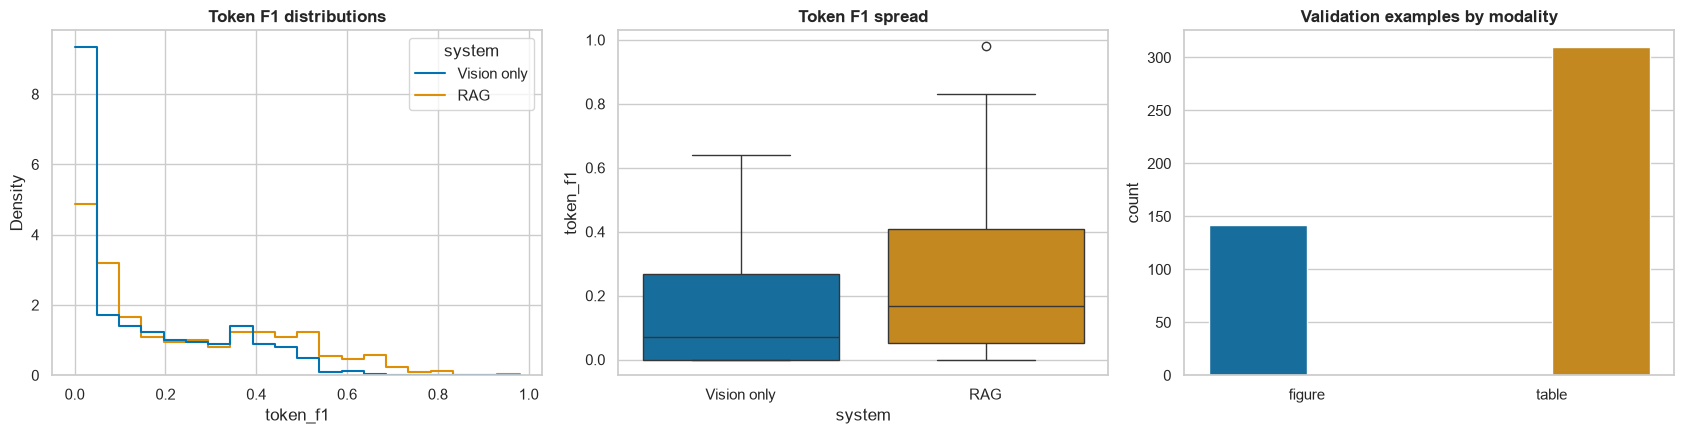

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
score_long = df.melt(
    id_vars=["row_id", "modality"],
    value_vars=["vision_only_token_f1", "rag_token_f1"],
    var_name="system", value_name="token_f1",
)
score_long["system"] = score_long["system"].map({
    "vision_only_token_f1": "Vision only",
    "rag_token_f1": "RAG",
})
sns.histplot(data=score_long, x="token_f1", hue="system", bins=20,
             stat="density", common_norm=False, element="step", fill=False, ax=axes[0])
axes[0].set_title("Token F1 distributions")
sns.boxplot(data=score_long, x="system", y="token_f1", hue="system",
            legend=False, ax=axes[1])
axes[1].set_title("Token F1 spread")
sns.countplot(data=df, x="modality", hue="modality", legend=False, ax=axes[2])
axes[2].set_title("Validation examples by modality")
axes[2].set_xlabel("")
plt.tight_layout()
plt.show()

## 5. Plot Relationships Between Variables

Compare paired scores directly, inspect running means in dataset row order (not a time trend), and compare modality-level averages.

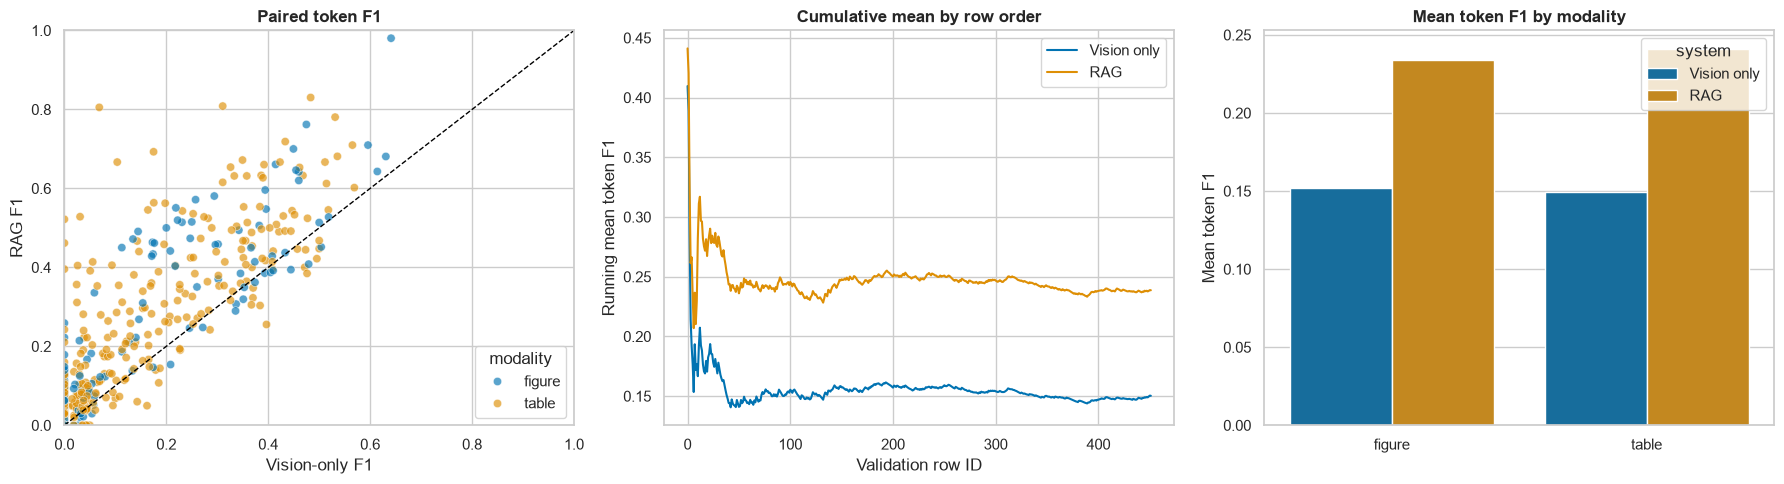

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="vision_only_token_f1", y="rag_token_f1",
                hue="modality", alpha=0.65, ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1)
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Paired token F1", xlabel="Vision-only F1", ylabel="RAG F1")

running = df.sort_values("row_id")[["row_id", "vision_only_token_f1", "rag_token_f1"]].copy()
running["vision_only_running_mean"] = running["vision_only_token_f1"].expanding().mean()
running["rag_running_mean"] = running["rag_token_f1"].expanding().mean()
axes[1].plot(running["row_id"], running["vision_only_running_mean"], label="Vision only")
axes[1].plot(running["row_id"], running["rag_running_mean"], label="RAG")
axes[1].set(title="Cumulative mean by row order", xlabel="Validation row ID", ylabel="Running mean token F1")
axes[1].legend()

modality_means = df.groupby("modality", observed=True)[
    ["vision_only_token_f1", "rag_token_f1"]
].mean().reset_index().melt(id_vars="modality", var_name="system", value_name="token_f1")
modality_means["system"] = modality_means["system"].map({
    "vision_only_token_f1": "Vision only", "rag_token_f1": "RAG"
})
sns.barplot(data=modality_means, x="modality", y="token_f1", hue="system", ax=axes[2])
axes[2].set(title="Mean token F1 by modality", xlabel="", ylabel="Mean token F1")
plt.tight_layout()
plt.show()

## 6. Build a Multi-Plot Dashboard

Use shared x-axes to compare per-example performance and deltas side by side.

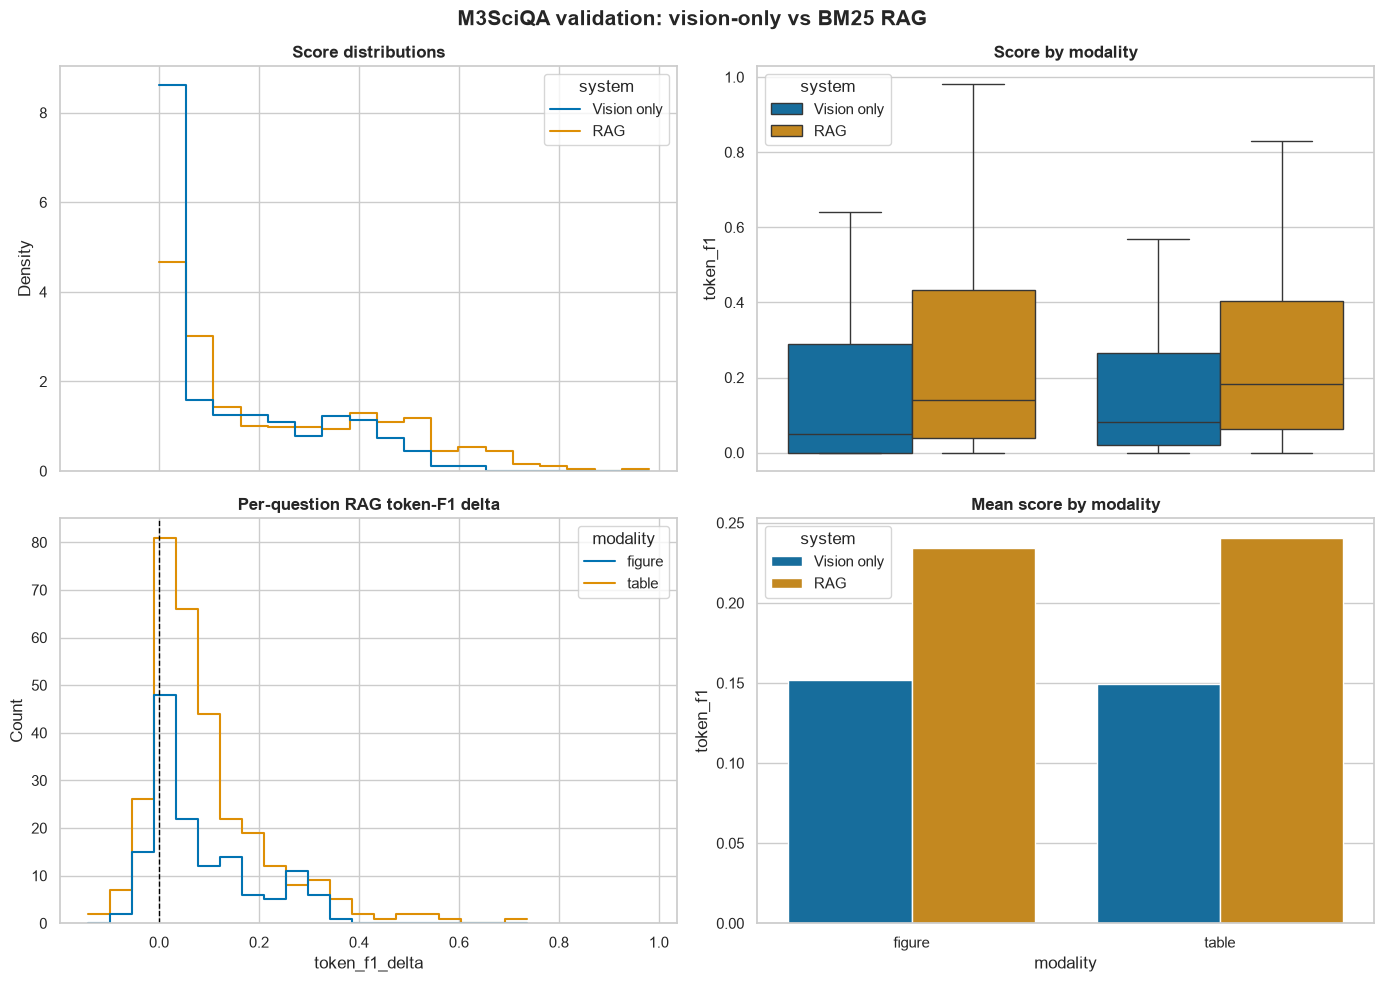

In [32]:
dashboard, axes = plt.subplots(2, 2, figsize=(14, 10), sharex="col")
sns.histplot(data=score_long, x="token_f1", hue="system", bins=18,
             stat="density", common_norm=False, element="step", fill=False, ax=axes[0, 0])
axes[0, 0].set_title("Score distributions")
sns.boxplot(data=score_long, x="modality", y="token_f1", hue="system", ax=axes[0, 1])
axes[0, 1].set_title("Score by modality")
sns.histplot(data=df, x="token_f1_delta", hue="modality", bins=20,
             element="step", fill=False, ax=axes[1, 0])
axes[1, 0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("Per-question RAG token-F1 delta")
sns.barplot(data=modality_means, x="modality", y="token_f1", hue="system", ax=axes[1, 1])
axes[1, 1].set_title("Mean score by modality")
for ax in axes.flat:
    ax.set_xlabel(ax.get_xlabel() or "")
dashboard.suptitle("M3SciQA validation: vision-only vs BM25 RAG", fontsize=15, fontweight="bold")
dashboard.tight_layout()
plt.show()

## 7. Add Interactive Controls for Exploration

Select a modality and metric to inspect paired scores and the largest per-question gains or regressions.

In [33]:
import ipywidgets as widgets
from IPython.display import display


def explore_scores(modality="All", metric="token_f1", show_worst=False):
    subset = df if modality == "All" else df[df["modality"] == modality]
    baseline_col = f"vision_only_{metric}"
    rag_col = f"rag_{metric}"
    delta_col = "token_f1_delta" if metric == "token_f1" else "rouge_l_delta"
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.scatterplot(data=subset, x=baseline_col, y=rag_col, hue="modality", alpha=0.7, ax=axes[0])
    axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[0].set(xlim=(0, 1), ylim=(0, 1), title=f"Paired {metric}", xlabel="Vision only", ylabel="RAG")
    axes[1].hist(subset[delta_col], bins=20, color="#2878B5", alpha=0.85)
    axes[1].axvline(0, color="black", linestyle="--")
    axes[1].set(title=f"{metric} delta distribution", xlabel="RAG minus vision-only", ylabel="Question count")
    plt.tight_layout()
    plt.show()
    display(subset.sort_values(delta_col, ascending=show_worst)[
        ["row_id", "modality", baseline_col, rag_col, delta_col]
    ].head(10))

widgets.interact(
    explore_scores,
    modality=widgets.Dropdown(options=["All", "figure", "table"], value="All", description="Modality"),
    metric=widgets.Dropdown(options=["token_f1", "rouge_l_f1"], value="token_f1", description="Metric"),
    show_worst=widgets.Checkbox(value=False, description="Show worst cases"),
);

interactive(children=(Dropdown(description='Modality', options=('All', 'figure', 'table'), value='All'), Dropd…

## 8. Save and Export Figures

Save reusable PNG/SVG charts and a CSV comparison table. When notebook cells are executed in the editor, their outputs are stored with the notebook.

In [34]:
FIGURE_DIR = REPO_ROOT / "llm_agents/evaluation/validation/qa/figures-agentic-run-2026-10-31"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Save the main dashboard in reusable raster and vector formats.
dashboard.savefig(FIGURE_DIR / "rag-vs-vision-only-dashboard.png", dpi=180, bbox_inches="tight")
dashboard.savefig(FIGURE_DIR / "rag-vs-vision-only-dashboard.svg", bbox_inches="tight")

comparison_table = df.groupby("modality", observed=True)[
    ["vision_only_em", "rag_em", "vision_only_token_f1", "rag_token_f1",
     "vision_only_rouge_l_f1", "rag_rouge_l_f1", "token_f1_delta", "rouge_l_delta"]
].mean().reset_index()
comparison_table.to_csv(FIGURE_DIR / "metric-comparison-by-modality.csv", index=False)
print(f"Exported dashboard figures and comparison CSV to {FIGURE_DIR}")

Exported dashboard figures and comparison CSV to /Users/sefika/projects/llm-agents/llm_agents/evaluation/validation/qa/figures-agentic-run-2026-10-31
